# 04 - Transformer on per-IP flow stories

Two models that look at a **story** = the last 32 flows of the same Source IP (ending at the flow we judge):

- **Model A** - a Transformer *classifier*: which of the 15 labels is this flow?
- **Model B** - a Transformer *autoencoder*: how unusual does this story look compared with normal (BENIGN) traffic?

Both feed the fuzzy layer in `05_fuzzy`.

In [1]:
%pip install -q torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Load the sequence arrays

`X` holds one row per flow (64 features), sorted by (split, Source IP, time), so each IP's flows sit next to each other.
We load it fully into RAM once (about 0.7 GB, float32) - much faster than reading from disk for every batch.

In [2]:
import os, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

X = np.load("data/seq/X.npy")                 # rows x 64, float32, fully in RAM
y = np.load("data/seq/y.npy")                 # label id per row (int8)
split = np.load("data/seq/split.npy")         # 0 train, 1 val, 2 test
grp_start = np.load("data/seq/grp_start.npy") # row where each row's IP group starts
meta = json.load(open("data/seq/meta.json"))
LABELS, SEQ_FEATS = meta["labels"], meta["features"]
FEATS = json.load(open("data/processed/features.json"))   # the 62 flow features (same as the RF used)

assert SEQ_FEATS[:62] == FEATS and SEQ_FEATS[62:] == ["new_dst_ip", "new_dst_port"]
PORT_COL = SEQ_FEATS.index("new_dst_port")
L = 32                     # story length
N_CLASSES = len(LABELS)    # 15, BENIGN = 0

print("X", X.shape, X.dtype, "| %.0f MB" % (X.nbytes / 1e6))
print(N_CLASSES, "labels:", LABELS)

X (2827761, 64) float32 | 724 MB
15 labels: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


## The story cutter (one story at a time)

`FlowWindows` is a normal PyTorch `Dataset`: give it an index, it cuts out the story for that row.
The story is the flows `max(group start, i-31) .. i`. If the IP has fewer than 32 earlier flows, the story is
**left-padded with zeros**, and a `mask` says which positions are real flows (True) and which are padding (False).
The flow being judged is always the **last** position.

In [3]:
class FlowWindows(Dataset):
    "Story (last L flows of the same IP, ending at row i) for each row in `rows`."
    def __init__(self, rows, L=32):
        self.rows, self.L = np.asarray(rows), L

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, k):
        i = self.rows[k]
        start = max(grp_start[i], i - self.L + 1)   # don't go back past the start of the IP group
        n = i + 1 - start                           # number of real flows
        win = np.zeros((self.L, X.shape[1]), dtype=np.float32)
        mask = np.zeros(self.L, dtype=bool)
        win[self.L - n:] = X[start:i + 1]           # real flows go at the end
        mask[self.L - n:] = True
        return win, mask, int(y[i])

## Step 1 - fast batch builder

Calling `FlowWindows` 512 times in a Python loop (that is what a `DataLoader` does) is slow, especially on Windows
where extra worker processes are expensive. `make_batch` builds **all stories of a batch at once** with numpy:

1. For each row `i`, the 32 row numbers of its story are `i-31, ..., i-1, i` (one row of a `[B, 32]` index table).
2. A position is real if its row number is still inside the same IP group (`>= grp_start[i]`).
3. Gather `X` at all those row numbers in one go (clipped so they are never negative), then zero out the fake ones.

The result is exactly what `FlowWindows` gives, just stacked into a batch. We check that below.

In [4]:
OFFS = np.arange(L - 1, -1, -1)      # 31, 30, ..., 0

def make_batch(rows):
    "Stories for many rows at once -> (windows [B,32,64] float32, mask [B,32] bool, labels [B] int64)."
    rows = np.asarray(rows, dtype=np.int64)
    idx = rows[:, None] - OFFS[None, :]               # [B, 32] row numbers of each story
    mask = idx >= grp_start[rows][:, None]             # True = real flow of the same IP
    win = X[np.maximum(idx, 0)]                        # gather (clip so the index is never negative)
    win[~mask] = 0.0                                   # padding positions become zeros
    return win, mask, y[rows].astype(np.int64)

# check: same result as FlowWindows (group starts, short groups and long groups)
rng = np.random.default_rng(0)
check_rows = np.concatenate([np.flatnonzero(grp_start == np.arange(len(X)))[:5],   # first flow of a group
                             rng.choice(len(X), 200, replace=False)])
fw = FlowWindows(check_rows)
w, m, lab = make_batch(check_rows)
for k in range(len(check_rows)):
    w1, m1, l1 = fw[k]
    assert np.array_equal(w[k], w1) and np.array_equal(m[k], m1) and lab[k] == l1
print("make_batch matches FlowWindows on", len(check_rows), "rows")

# speed comparison for one batch of 512
rows512 = rng.choice(len(X), 512, replace=False)
t = time.time(); _ = [FlowWindows(rows512)[k] for k in range(512)]; t_loop = time.time() - t
t = time.time(); _ = make_batch(rows512); t_fast = time.time() - t
print(f"512 stories: FlowWindows loop {t_loop*1000:.0f} ms, make_batch {t_fast*1000:.0f} ms")

make_batch matches FlowWindows on 205 rows
512 stories: FlowWindows loop 16 ms, make_batch 9 ms


## Step 2 - training sample and class weights

The train split has 1.36 M BENIGN rows but only 13 SQL Injection rows. Training on everything would be slow and
dominated by BENIGN, so we take a sample:

- **train_idx** (split 0): up to 200k BENIGN + up to 50k per attack class (small classes are kept fully).
- **val_idx** (split 1): up to 100k BENIGN + up to 20k per attack - used after each epoch to pick the best epoch.

Even after sampling, classes are unbalanced, so the loss gives rare classes a bigger weight:
`w_c = sqrt(N / (K * n_c))` (N = sample size, K = 15 classes, n_c = rows of class c). The square root keeps the
weights milder than full "balanced" weights, so a class with 7 rows doesn't completely dominate.

In [5]:
def sample_rows(split_id, benign_cap, attack_cap, seed=42):
    "Row numbers from one split: up to benign_cap BENIGN rows and up to attack_cap rows per attack class."
    rng = np.random.default_rng(seed)
    parts = []
    in_split = split == split_id
    for c in range(N_CLASSES):
        rows = np.flatnonzero(in_split & (y == c))
        cap = benign_cap if c == 0 else attack_cap
        if len(rows) > cap:
            rows = rng.choice(rows, cap, replace=False)
        parts.append(rows)
    return np.sort(np.concatenate(parts))

TRAIN_CAPS = (200_000, 50_000)
VAL_CAPS = (100_000, 20_000)
train_idx = sample_rows(0, *TRAIN_CAPS)
val_idx = sample_rows(1, *VAL_CAPS)

def class_weights(rows):
    n_c = np.bincount(y[rows], minlength=N_CLASSES)
    return torch.tensor(np.sqrt(len(rows) / (N_CLASSES * n_c)), dtype=torch.float32)

class_w = class_weights(train_idx)
print("train_idx", len(train_idx), "| val_idx", len(val_idx))
pd.DataFrame({"train n": np.bincount(y[train_idx], minlength=N_CLASSES),
              "val n": np.bincount(y[val_idx], minlength=N_CLASSES),
              "weight": class_w.numpy().round(2)}, index=LABELS)

train_idx 373767 | val_idx 167919


,train n,val n,weight
BENIGN,200000,100000,0.350000
Bot,1174,391,4.610000
DDoS,50000,20000,0.710000
DoS GoldenEye,6176,2059,2.010000
DoS Hulk,50000,20000,0.710000
DoS Slowhttptest,3300,1100,2.750000
DoS slowloris,3478,1159,2.680000
FTP-Patator,4761,1587,2.290000
Heartbleed,7,2,59.660000
Infiltration,22,7,33.650002


## Step 3 - Model A: Transformer classifier

How it works, compared with a CNN:

- **Input projection**: a `Linear(64 -> 64)` turns each flow's 64 features into a 64-number "token" (like a 1x1 conv).
- **Positional embedding**: attention by itself has no idea of order (it sees a *set*). So we add a learnable vector
  for each of the 32 positions, which tells the model "this flow is the 3rd-last", etc.
- **Self-attention**: every flow looks at every other real flow in the story and decides how much each one matters.
  Unlike a CNN's fixed local kernel, the "receptive field" is the whole story from the first layer, and the weights
  depend on the content. 4 heads = 4 different ways of looking at the story in parallel.
- **Padding mask**: `src_key_padding_mask = ~mask` tells attention to ignore the zero padding.
- **Pooling**: we join (a) the output at the **last position** (the flow being judged, now enriched with context)
  and (b) the **average over real flows** (a summary of the whole story), then a `Linear` gives 15 class scores.

In [6]:
torch.set_num_threads(os.cpu_count())

def masked_mean(h, mask):
    "Average of h [B,32,d] over the real positions only."
    m = mask.unsqueeze(-1).float()
    return (h * m).sum(1) / m.sum(1).clamp(min=1)

class StoryEncoder(nn.Module):
    "Projection + positional embedding + 2-layer Transformer encoder. Shared by Model A and Model B."
    def __init__(self, n_feat=64, d=64, heads=4, ff=128, layers=2, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(n_feat, d)
        self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)       # one learnable vector per position
        layer = nn.TransformerEncoderLayer(d, heads, ff, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers)

    def forward(self, x, mask):
        h = self.proj(x) + self.pos
        return self.encoder(h, src_key_padding_mask=~mask)      # True in the padding mask = ignore

class TransformerClassifier(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.enc = StoryEncoder(d=d)
        self.head = nn.Linear(2 * d, N_CLASSES)

    def forward(self, x, mask):
        h = self.enc(x, mask)
        pooled = torch.cat([h[:, -1], masked_mean(h, mask)], dim=1)   # last flow + story summary
        return self.head(pooled)

def to_torch(win, mask, lab):
    return torch.from_numpy(win), torch.from_numpy(mask), torch.from_numpy(lab)

@torch.no_grad()
def predict_proba(model, rows, chunk=8192):
    "Class probabilities [n, 15] for the given rows, in chunks."
    model.eval()
    out = []
    for s in range(0, len(rows), chunk):
        xb, mb, _ = to_torch(*make_batch(rows[s:s + chunk]))
        out.append(torch.softmax(model(xb, mb), dim=1).numpy())
    return np.concatenate(out)

n_params = sum(p.numel() for p in TransformerClassifier().parameters())
print("Model A parameters:", n_params)

Model A parameters: 75087


### Is an epoch fast enough?

Before the real training we time 20 training steps and estimate one epoch. If it would take more than 15 minutes,
we halve the sample caps.

In [7]:
BATCH = 512

def time_epoch(rows, n_steps=20):
    "Estimated minutes for one training epoch of Model A over `rows`."
    m = TransformerClassifier()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss(weight=class_w)
    m.train()
    n_steps = min(n_steps, int(np.ceil(len(rows) / BATCH)))
    t = time.time()
    for s in range(n_steps):
        xb, mb, yb = to_torch(*make_batch(rows[s * BATCH:(s + 1) * BATCH]))
        loss = loss_fn(m(xb, mb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    return (time.time() - t) / n_steps * np.ceil(len(rows) / BATCH) / 60

est = time_epoch(np.random.default_rng(1).permutation(train_idx))
print(f"estimated epoch time: {est:.1f} min for {len(train_idx)} stories")
if est > 15:
    TRAIN_CAPS = (TRAIN_CAPS[0] // 2, TRAIN_CAPS[1] // 2)
    train_idx = sample_rows(0, *TRAIN_CAPS)
    class_w = class_weights(train_idx)
    print(">>> epoch would take over 15 min: halved train caps to", TRAIN_CAPS, "->", len(train_idx), "stories")

estimated epoch time: 21.6 min for 373767 stories
>>> epoch would take over 15 min: halved train caps to (100000, 25000) -> 198767 stories


### Train Model A

- Loss: cross-entropy with the class weights. Optimiser: AdamW, lr 1e-3, batch 512.
- Each epoch shuffles `train_idx`. After each epoch we measure **macro F1 on val_idx** (every class counts equally).
- **Early stopping**: if val macro F1 doesn't improve for 2 epochs in a row, stop. We keep the weights of the best epoch.

In [8]:
from sklearn.metrics import f1_score

EPOCHS, PATIENCE = 8, 2
torch.manual_seed(42)
model = TransformerClassifier()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=class_w)
shuffle_rng = np.random.default_rng(42)

best_f1, best_state, bad_epochs, history = -1.0, None, 0, []
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    order = shuffle_rng.permutation(train_idx)
    total_loss = 0.0
    for s in range(0, len(order), BATCH):
        xb, mb, yb = to_torch(*make_batch(order[s:s + BATCH]))
        loss = loss_fn(model(xb, mb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item() * len(yb)
    train_min = (time.time() - t0) / 60

    val_f1 = f1_score(y[val_idx], predict_proba(model, val_idx).argmax(1), average="macro")
    history.append((epoch, total_loss / len(order), val_f1, (time.time() - t0) / 60))
    print(f"epoch {epoch}: train loss {total_loss / len(order):.4f} | val macro F1 {val_f1:.4f} | "
          f"train {train_min:.1f} min, total {(time.time() - t0) / 60:.1f} min")
    if epoch == 1:
        print(f"   (first epoch took {(time.time() - t0) / 60:.1f} min)")

    if val_f1 > best_f1:
        best_f1, bad_epochs = val_f1, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("early stopping")
            break

model.load_state_dict(best_state)
Path("models").mkdir(exist_ok=True)
torch.save(best_state, "models/transformer_clf.pt")
print(f"best val macro F1 {best_f1:.4f} -> saved models/transformer_clf.pt")

D:\fuzzy_project\.venv\Lib\site-packages\torch\nn\modules\transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


epoch 1: train loss 0.1698 | val macro F1 0.7764 | train 5.5 min, total 6.5 min
   (first epoch took 6.5 min)


epoch 2: train loss 0.0244 | val macro F1 0.7939 | train 5.3 min, total 6.1 min


epoch 3: train loss 0.0154 | val macro F1 0.8051 | train 4.7 min, total 5.7 min


epoch 4: train loss 0.0120 | val macro F1 0.8249 | train 5.3 min, total 6.4 min


epoch 5: train loss 0.0095 | val macro F1 0.8515 | train 5.3 min, total 6.2 min


epoch 6: train loss 0.0132 | val macro F1 0.8037 | train 4.9 min, total 5.9 min


epoch 7: train loss 0.0097 | val macro F1 0.7912 | train 4.8 min, total 5.8 min
early stopping
best val macro F1 0.8515 -> saved models/transformer_clf.pt


## Step 4 - Evaluate Model A on the full validation split

`val_idx` was a sample. Now we score **every** val row (all 565k), so the numbers are honest and comparable.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix

val_rows = np.flatnonzero(split == 1)
t = time.time()
val_proba = predict_proba(model, val_rows)
val_pred = val_proba.argmax(1)
y_val = y[val_rows].astype(np.int64)
print(f"scored {len(val_rows)} val stories in {(time.time() - t) / 60:.1f} min\n")
print(classification_report(y_val, val_pred, labels=range(N_CLASSES), target_names=LABELS,
                            digits=3, zero_division=0))

scored 565550 val stories in 4.5 min



                            precision    recall  f1-score   support

                    BENIGN      1.000     0.998     0.999    454240
                       Bot      0.284     0.734     0.410       391
                      DDoS      0.999     1.000     1.000     25605
             DoS GoldenEye      0.995     0.999     0.997      2059
                  DoS Hulk      1.000     1.000     1.000     46025
          DoS Slowhttptest      0.988     0.935     0.961      1100
             DoS slowloris      0.898     0.996     0.944      1159
               FTP-Patator      0.999     0.998     0.999      1587
                Heartbleed      0.000     0.000     0.000         2
              Infiltration      0.133     0.857     0.231         7
                  PortScan      1.000     1.000     1.000     31761
               SSH-Patator      0.994     0.999     0.997      1179
  Web Attack - Brute Force      0.938     1.000     0.968       301
Web Attack - Sql Injection      0.214     0.750

### Confusion matrix

Each row is a true class and shows where its flows went, as a **share of that row** (rows sum to 1). With 454k
BENIGN and 2 Heartbleed rows, raw counts would hide the small classes.

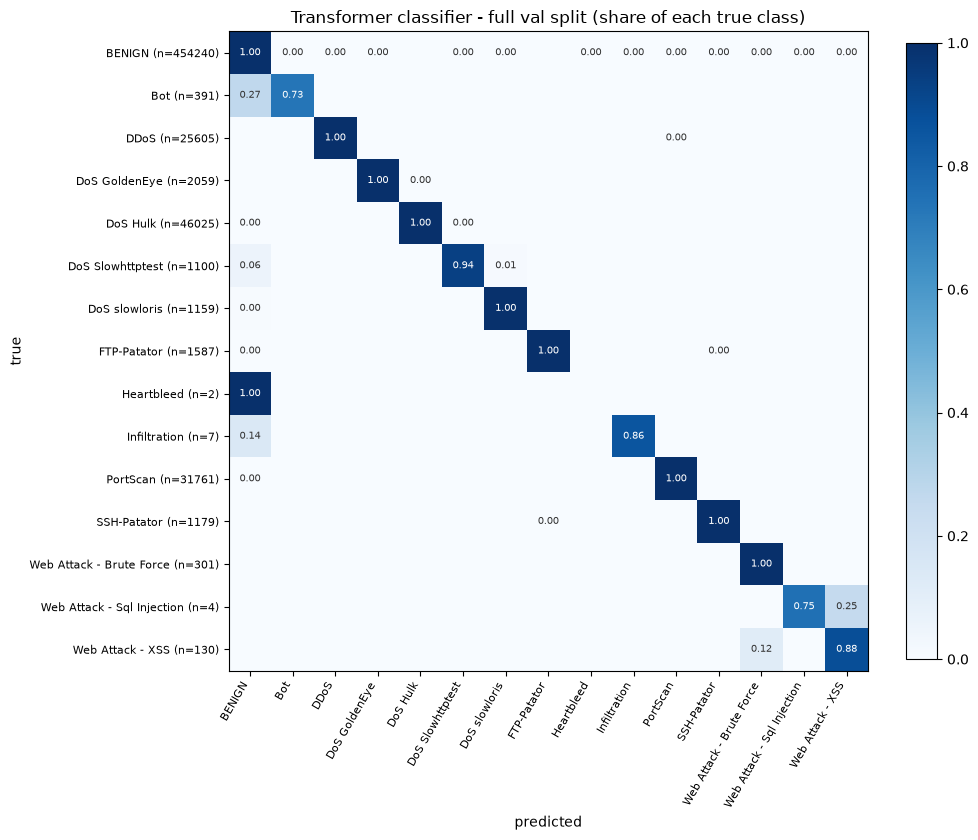

In [10]:
cm = confusion_matrix(y_val, val_pred, labels=range(N_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

out_dir = Path("results/transformer")
out_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] > 0:
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm_norm[i, j] > 0.6 else "#333333")
ax.set_xticks(range(N_CLASSES), LABELS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(N_CLASSES), [f"{lab} (n={n})" for lab, n in zip(LABELS, cm.sum(1))], fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Transformer classifier - full val split (share of each true class)")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
fig.savefig(out_dir / "cm_val.png", dpi=130)
plt.show()

### Fair comparison with the Random Forest

The RF baseline (03) was evaluated on the *deduplicated* flow data, so its 0.777 isn't on the same rows.
Here we run the saved RF on **exactly the same val rows** with the same 62 features in the same order
(`X[val_rows, :62]`), so the only difference is the model: one flow (RF) vs a story of up to 32 flows (Transformer).

In [11]:
import joblib

rf = joblib.load("models/rf_baseline.joblib")
assert list(rf.feature_names_in_) == FEATS
t = time.time()
rf_pred_names = rf.predict(pd.DataFrame(X[val_rows, :62], columns=FEATS))
rf_pred = pd.Categorical(rf_pred_names, categories=LABELS).codes.astype(np.int64)
print(f"RF predicted {len(val_rows)} rows in {(time.time() - t) / 60:.1f} min")
del rf, rf_pred_names
_ = gc.collect()

f1_rf = f1_score(y_val, rf_pred, labels=range(N_CLASSES), average=None, zero_division=0)
f1_tr = f1_score(y_val, val_pred, labels=range(N_CLASSES), average=None, zero_division=0)
compare = pd.DataFrame({"val n": np.bincount(y_val, minlength=N_CLASSES),
                        "RF F1": f1_rf.round(3), "Transformer F1": f1_tr.round(3)}, index=LABELS)
compare["better"] = np.where(f1_tr > f1_rf, "<-- Transformer", np.where(f1_tr < f1_rf, "RF", "same"))
compare.loc["MACRO F1"] = [len(y_val), round(f1_rf.mean(), 3), round(f1_tr.mean(), 3),
                           "<-- Transformer" if f1_tr.mean() > f1_rf.mean() else "RF"]
compare

RF predicted 565550 rows in 0.1 min


,val n,RF F1,Transformer F1,better
BENIGN,454240,0.998,0.999,<-- Transformer
Bot,391,0.434,0.410,RF
DDoS,25605,0.999,1.000,<-- Transformer
DoS GoldenEye,2059,0.979,0.997,<-- Transformer
DoS Hulk,46025,0.993,1.000,<-- Transformer
DoS Slowhttptest,1100,0.873,0.961,<-- Transformer
DoS slowloris,1159,0.992,0.944,RF
FTP-Patator,1587,0.966,0.999,<-- Transformer
Heartbleed,2,1.000,0.000,RF
Infiltration,7,0.455,0.231,RF


## Step 5 - Model B: Transformer autoencoder (anomaly detector)

The classifier can only recognise attacks it has seen. An **autoencoder** learns what *normal* looks like:

- It is trained **only on BENIGN stories**: squeeze the story into a small summary, then rebuild the story from it.
- **Encoder**: the same projection + positional embedding + 2-layer Transformer as Model A, then the average over
  real flows -> `Linear` to a **16-number bottleneck**. One small vector for the whole story means it can't just
  copy the input through; it has to learn the typical patterns of normal traffic.
- **Decoder**: for each of the 32 positions, take the bottleneck vector + that position's embedding, and a small MLP
  (16+64 -> 128 -> 64) rebuilds that flow's 64 features.
- **Loss**: mean squared error over the **real** positions only (padding is ignored).

Afterwards, a story that the model rebuilds badly (high error) looks unlike normal traffic -> anomaly.
The error is turned into a **percentile** against BENIGN val stories: 0.5 = a typical benign story, 0.99 = more
unusual than 99% of benign stories.

In [12]:
class TransformerAE(nn.Module):
    def __init__(self, d=64, z=16):
        super().__init__()
        self.enc = StoryEncoder(d=d)
        self.to_z = nn.Linear(d, z)                                  # 16-number bottleneck
        self.dec_pos = nn.Parameter(torch.randn(1, L, d) * 0.02)     # where in the story to rebuild
        self.dec = nn.Sequential(nn.Linear(z + d, 128), nn.ReLU(), nn.Linear(128, X.shape[1]))

    def forward(self, x, mask):
        z = self.to_z(masked_mean(self.enc(x, mask), mask))          # [B, 16]
        z_rep = z.unsqueeze(1).expand(-1, L, -1)                     # same vector for each position
        pos = self.dec_pos.expand(len(x), -1, -1)
        return self.dec(torch.cat([z_rep, pos], dim=-1))             # [B, 32, 64] rebuilt story

def story_error(rec, x, mask):
    "Mean squared error per story [B], over real positions only."
    per_pos = ((rec - x) ** 2).mean(-1)                              # [B, 32]
    m = mask.float()
    return (per_pos * m).sum(1) / m.sum(1).clamp(min=1)

@torch.no_grad()
def ae_score(model, rows, chunk=8192):
    "Anomaly score (story reconstruction error) for the given rows."
    model.eval()
    out = []
    for s in range(0, len(rows), chunk):
        xb, mb, _ = to_torch(*make_batch(rows[s:s + chunk]))
        out.append(story_error(model(xb, mb), xb, mb).numpy())
    return np.concatenate(out)

rng = np.random.default_rng(42)
ae_train_idx = np.sort(rng.choice(np.flatnonzero((split == 0) & (y == 0)), 200_000, replace=False))
ae_val_idx = np.sort(rng.choice(np.flatnonzero((split == 1) & (y == 0)), 50_000, replace=False))
print("AE train (BENIGN)", len(ae_train_idx), "| AE val (BENIGN)", len(ae_val_idx))

AE train (BENIGN) 200000 | AE val (BENIGN) 50000


In [13]:
torch.manual_seed(42)
ae = TransformerAE()
opt = torch.optim.AdamW(ae.parameters(), lr=1e-3)
shuffle_rng = np.random.default_rng(42)

best_err, best_state, bad_epochs = np.inf, None, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    ae.train()
    order = shuffle_rng.permutation(ae_train_idx)
    total_loss = 0.0
    for s in range(0, len(order), BATCH):
        xb, mb, _ = to_torch(*make_batch(order[s:s + BATCH]))
        rec = ae(xb, mb)
        m = mb.unsqueeze(-1).float()
        loss = (((rec - xb) ** 2) * m).sum() / (m.sum() * xb.shape[-1])   # MSE over real positions
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item() * len(xb)

    val_err = ae_score(ae, ae_val_idx).mean()
    print(f"epoch {epoch}: train loss {total_loss / len(order):.4f} | BENIGN val error {val_err:.4f} | "
          f"{(time.time() - t0) / 60:.1f} min")
    if val_err < best_err:
        best_err, bad_epochs = val_err, 0
        best_state = {k: v.clone() for k, v in ae.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("early stopping")
            break

ae.load_state_dict(best_state)
torch.save(best_state, "models/transformer_ae.pt")
print(f"best BENIGN val error {best_err:.4f} -> saved models/transformer_ae.pt")

epoch 1: train loss 0.5726 | BENIGN val error 0.4712 | 5.8 min


epoch 2: train loss 0.4835 | BENIGN val error 0.4318 | 6.4 min


epoch 3: train loss 0.4575 | BENIGN val error 0.4143 | 6.7 min


epoch 4: train loss 0.4423 | BENIGN val error 0.4055 | 6.7 min


epoch 5: train loss 0.4349 | BENIGN val error 0.4007 | 7.3 min


epoch 6: train loss 0.4283 | BENIGN val error 0.3951 | 7.0 min


epoch 7: train loss 0.4234 | BENIGN val error 0.3913 | 6.7 min


epoch 8: train loss 0.4202 | BENIGN val error 0.3890 | 6.8 min
best BENIGN val error 0.3890 -> saved models/transformer_ae.pt


### Anomaly scores on the full val split

- `anomaly_raw` = reconstruction error of the story.
- `anomaly_pct` = share of BENIGN val stories with a *lower or equal* error (0 = very normal, 1 = more unusual than every benign val story).
- **ROC-AUC** = chance that a random attack story gets a higher score than a random BENIGN story (0.5 = useless, 1.0 = perfect).

In [14]:
from sklearn.metrics import roc_auc_score

t = time.time()
val_ae = ae_score(ae, val_rows)
print(f"scored {len(val_rows)} val stories in {(time.time() - t) / 60:.1f} min")

benign_ref = np.sort(val_ae[y_val == 0])          # reference: all BENIGN val scores

def to_percentile(scores):
    return np.searchsorted(benign_ref, scores, side="right") / len(benign_ref)

val_pct = to_percentile(val_ae)
is_benign = y_val == 0
print(f"ROC-AUC BENIGN vs all attacks: {roc_auc_score(~is_benign, val_ae):.3f}")

rows_out = []
for c, lab in enumerate(LABELS):
    sel = y_val == c
    auc = np.nan if c == 0 else roc_auc_score(sel[is_benign | sel], val_ae[is_benign | sel])
    rows_out.append({"label": lab, "n": sel.sum(), "mean pct": val_pct[sel].mean(),
                     "median pct": np.median(val_pct[sel]), "AUC vs BENIGN": auc})
pd.DataFrame(rows_out).set_index("label").round(3)

scored 565550 val stories in 5.4 min


ROC-AUC BENIGN vs all attacks: 0.567


,n,mean pct,median pct,AUC vs BENIGN
label,,,,
BENIGN,454240,0.500,0.500,NaN
Bot,391,0.522,0.715,0.522
DDoS,25605,0.813,0.893,0.813
DoS GoldenEye,2059,0.645,0.727,0.645
DoS Hulk,46025,0.689,0.850,0.689
DoS Slowhttptest,1100,0.930,0.957,0.930
DoS slowloris,1159,0.946,0.993,0.946
FTP-Patator,1587,0.861,0.871,0.861
Heartbleed,2,0.981,0.981,0.981


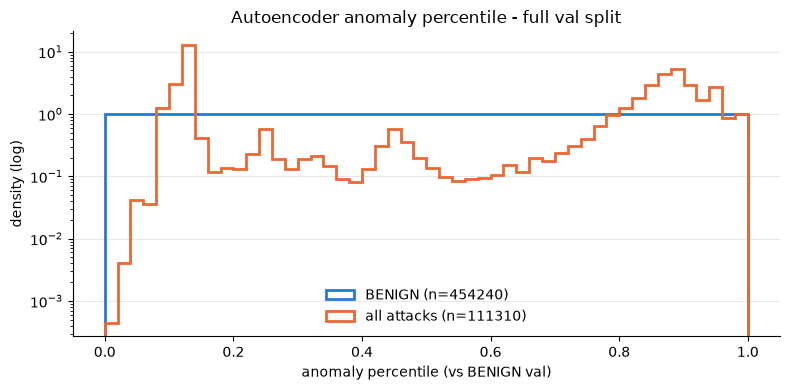

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 51)
ax.hist(val_pct[is_benign], bins=bins, density=True, histtype="step", linewidth=2,
        color="#2a78d6", label=f"BENIGN (n={is_benign.sum()})")
ax.hist(val_pct[~is_benign], bins=bins, density=True, histtype="step", linewidth=2,
        color="#eb6834", label=f"all attacks (n={(~is_benign).sum()})")
ax.set_yscale("log")
ax.set_xlabel("anomaly percentile (vs BENIGN val)"); ax.set_ylabel("density (log)")
ax.set_title("Autoencoder anomaly percentile - full val split")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(out_dir / "ae_scores.png", dpi=130)
plt.show()

### Unknown-attack check

Classes with very few training rows behave almost like *unknown* attacks for the classifier. Does the autoencoder,
which never saw any attack, still find them unusual? "% above p95" = share of the class that is more unusual than
95% of BENIGN val stories (for BENIGN itself this is 5% by definition).

In [16]:
for lab in ["Heartbleed", "Infiltration", "Web Attack - Sql Injection", "Bot"]:
    sel = y_val == LABELS.index(lab)
    print(f"{lab:28s} n={sel.sum():4d} | median percentile {np.median(val_pct[sel]):.3f} | "
          f"above p95 of BENIGN: {100 * (val_pct[sel] > 0.95).mean():5.1f} %")

Heartbleed                   n=   2 | median percentile 0.981 | above p95 of BENIGN: 100.0 %
Infiltration                 n=   7 | median percentile 0.971 | above p95 of BENIGN:  71.4 %
Web Attack - Sql Injection   n=   4 | median percentile 0.595 | above p95 of BENIGN:   0.0 %
Bot                          n= 391 | median percentile 0.715 | above p95 of BENIGN:   3.8 %


## Step 6 - Outputs for the fuzzy layer

For every val and test row we save one table with everything `05_fuzzy` needs:

- `p_<class>`: the classifier's 15 probabilities, `pred` (most likely class), `p_attack = 1 - p_BENIGN`
- `anomaly_raw`, `anomaly_pct`: the autoencoder score and its percentile vs BENIGN val
- `scan_evidence`: share of the story's real flows that went to a *new destination port* (port scans are close to 1)
- `n_real`: how many real flows the story has (1 = no history -> less context, the fuzzy layer may trust it less)

**Test metrics are not computed here** - the test split stays locked until the end of the project.

In [17]:
def story_stats(rows, chunk=65536):
    "scan_evidence (mean new_dst_port over real flows) and n_real for each row, without building full stories."
    scan, n_real = [], []
    for s in range(0, len(rows), chunk):
        r = rows[s:s + chunk].astype(np.int64)
        idx = r[:, None] - OFFS[None, :]
        mask = idx >= grp_start[r][:, None]
        port = X[np.maximum(idx, 0), PORT_COL] * mask
        n = mask.sum(1)
        scan.append(port.sum(1) / n); n_real.append(n)
    return np.concatenate(scan).astype(np.float32), np.concatenate(n_real).astype(np.int16)

def fuzzy_table(rows, proba, anomaly_raw):
    df = pd.DataFrame({"row": rows, "label": pd.Categorical.from_codes(y[rows], LABELS)})
    for c, lab in enumerate(LABELS):
        df[f"p_{lab}"] = proba[:, c].astype(np.float32)
    df["pred"] = pd.Categorical.from_codes(proba.argmax(1), LABELS)
    df["p_attack"] = (1 - proba[:, 0]).astype(np.float32)
    df["anomaly_raw"] = anomaly_raw.astype(np.float32)
    df["anomaly_pct"] = to_percentile(anomaly_raw).astype(np.float32)
    df["scan_evidence"], df["n_real"] = story_stats(rows)
    return df

Path("data/fuzzy").mkdir(parents=True, exist_ok=True)

# val: reuse the scores computed above
fz_val = fuzzy_table(val_rows, val_proba, val_ae)
fz_val.to_parquet("data/fuzzy/val.parquet", index=False)
print("saved data/fuzzy/val.parquet", fz_val.shape)

# test: score and save only - no metrics
t = time.time()
test_rows = np.flatnonzero(split == 2)
fz_test = fuzzy_table(test_rows, predict_proba(model, test_rows), ae_score(ae, test_rows))
fz_test.to_parquet("data/fuzzy/test.parquet", index=False)
print("saved data/fuzzy/test.parquet", fz_test.shape, f"in {(time.time() - t) / 60:.1f} min")
print(list(fz_val.columns))
del fz_test
_ = gc.collect()

saved data/fuzzy/val.parquet (565550, 23)


saved data/fuzzy/test.parquet (565545, 23) in 10.4 min
['row', 'label', 'p_BENIGN', 'p_Bot', 'p_DDoS', 'p_DoS GoldenEye', 'p_DoS Hulk', 'p_DoS Slowhttptest', 'p_DoS slowloris', 'p_FTP-Patator', 'p_Heartbleed', 'p_Infiltration', 'p_PortScan', 'p_SSH-Patator', 'p_Web Attack - Brute Force', 'p_Web Attack - Sql Injection', 'p_Web Attack - XSS', 'pred', 'p_attack', 'anomaly_raw', 'anomaly_pct', 'scan_evidence', 'n_real']


In [18]:
# sanity check on val: PortScan stories should have much higher scan_evidence than BENIGN
fz_val.groupby("label", observed=True)[["p_attack", "anomaly_pct", "scan_evidence", "n_real"]].mean().round(3)

,p_attack,anomaly_pct,scan_evidence,n_real
label,,,,
BENIGN,0.004,0.500,0.365,29.641
Bot,0.725,0.522,0.577,30.731
DDoS,1.000,0.813,0.001,32.000
DoS GoldenEye,1.000,0.645,0.000,32.000
DoS Hulk,1.000,0.689,0.000,32.000
DoS Slowhttptest,0.937,0.930,0.000,32.000
DoS slowloris,0.994,0.946,0.014,32.000
FTP-Patator,1.000,0.861,0.003,31.687
Heartbleed,0.428,0.981,0.891,32.000


### Model file sizes

Model files should be small. Anything over 50 MB in `models/` goes into `.gitignore`.

In [19]:
ignore = Path(".gitignore").read_text(encoding="utf-8-sig").splitlines()
for f in sorted(Path("models").iterdir()):
    mb = f.stat().st_size / 1e6
    entry = f.as_posix()
    if mb > 50 and entry not in ignore:
        ignore.append(entry)
        print("added to .gitignore:", entry)
    print(f"{entry:32s} {mb:8.2f} MB")
_ = Path(".gitignore").write_text("\n".join(ignore) + "\n", encoding="utf-8")

models/rf_baseline.joblib           55.67 MB
models/scaler.joblib                 0.00 MB
models/transformer_ae.pt             0.39 MB
models/transformer_clf.pt            0.31 MB


90

## Transformer summary

**The two models**
- **Model A (classifier):** reads a *story* (the last up-to-32 flows of the same Source IP) with a small 2-layer Transformer (75k parameters) and predicts one of 15 labels for the last flow.
- **Model B (autoencoder):** trained only on BENIGN stories. It squeezes a story into 16 numbers and rebuilds it. A badly rebuilt story = unusual = possible attack. The error is turned into a percentile vs BENIGN val (0 = very normal, 1 = more unusual than all benign).

**Training notes**
- The timing check estimated 21.6 min per epoch on the full sample, so the train caps were **halved** to 100k BENIGN + 25k per attack (199k stories). Epochs then took about 6 min.
- Model A stopped early after epoch 7 (best = epoch 5, val_idx macro F1 0.852). Model B ran all 8 epochs, and its BENIGN val error was still slowly improving (0.471 -> 0.389).

**Model A vs Random Forest (full val split, same 565k rows, same 62 features)**
- Macro F1: **Transformer 0.781 vs RF 0.773.** Close overall, but they win on different classes.
- The Transformer is clearly better on the **web attacks**: XSS 0.871 vs 0.303, Web Brute Force 0.968 vs 0.731, SQL Injection 0.333 vs 0.000. Also SSH-Patator 0.997 vs 0.868 and DoS Slowhttptest 0.961 vs 0.873. The story context (what the same IP did just before) helps tell these apart.
- The RF is better on **Heartbleed** (1.0 vs 0.0: 7 training rows, both val rows predicted BENIGN), **Infiltration** (0.455 vs 0.231), **Bot** (0.434 vs 0.410) and slowloris (0.992 vs 0.944).
- The weak spot is **precision on rare classes**: Bot recall is 0.73 but precision 0.28, and Infiltration recall is 0.86 but precision 0.13. Even 0.1% of 454k BENIGN rows is hundreds of false alarms.

**Model B: how well the anomaly score separates attacks**
- Overall ROC-AUC BENIGN vs all attacks is only **0.567**. That is mostly because of **PortScan** (28% of val attacks): its flows are tiny and regular, so they look *more normal* than benign (median percentile 0.12, AUC 0.13). Without PortScan the AUC is 0.741.
- Strong separation for SSH-Patator (0.98), Heartbleed (0.98), Infiltration (0.96), slowloris (0.95), Slowhttptest (0.93), FTP-Patator (0.86) and DDoS (0.81).
- Weak for the web attacks (XSS 0.45, SQL Injection 0.58), Bot (0.52) and PortScan. Those look like normal web or scan traffic in shape, not in content.
- **Unknown-attack check:** Heartbleed (median percentile 0.98, 2/2 above the BENIGN 95th percentile) and Infiltration (0.97, 71% above p95) are exactly the rare classes the classifier misses, so the two models complement each other. SQL Injection (0.60, 0%) and Bot (0.72, 3.8%) are not caught by the anomaly score.
- PortScan is caught instead by **scan_evidence** (mean 1.00 for PortScan vs 0.37 for BENIGN).

**Files for 05_fuzzy**
- `data/fuzzy/val.parquet` (565,550 rows) and `data/fuzzy/test.parquet` (565,545 rows): `row`, `label`, `p_<class>` x15, `pred`, `p_attack`, `anomaly_raw`, `anomaly_pct`, `scan_evidence`, `n_real`. **No test metrics were computed.**
- `models/transformer_clf.pt` (0.31 MB) and `models/transformer_ae.pt` (0.39 MB).
- Plots: `results/transformer/cm_val.png` and `results/transformer/ae_scores.png`.